#Read me

* order of quark coupling array xq
* params verification



# Initialize

In [ ]:
import photoproductionmodel as pm
import numpy as np
import scipy
import matplotlib.pyplot as plt

mp = 0.9382720813
e = 0.303
m_pi_charged = 0.140 #charged pion

# gauge coupling charges
gauge_couplings = {"A'":np.array([2/3,-1/3,-1/3,-1,-1,0,0,0]),
                   "B-L":np.array([1/3,1/3,1/3,-1,-1,-1,-1,-1]),
                   "B":np.array([1/3,1/3,1/3,-e**2/(4*np.pi)**2,-e**2/(4*np.pi)**2,0,0,0]),
                   "Chargephobic":np.array([-1/(3*np.sqrt(2)),np.sqrt(2)/3,np.sqrt(2)/3,0,0,-1/np.sqrt(2),-1/np.sqrt(2),-1/np.sqrt(2)])}

malcolm_params = np.array([11.8035243067,
                           4.0375821561,
                           0.8501802514,
                           0.7564022768,
                           0.8600896137,
                           0.8086569351,
                           0.6189396544,
                           0.6606751651,
                           3.0105358915,
                           1.944893166,
                           6.8313599991,
                           3.102950432,
                           1.1160097169,
                           1.2982535382,
                           0.8747976834,
                           0.8876128185,
                           0.8360851833,
                           0.8145016121,
                           3.3749578534,
                           4.0129062317,
                           -8.9194775041,
                           8.6359589795,
                           0.9822559621])

# Sample EX,cosX

In [ ]:
def P(s_tot,EX,cosX,params,mX,xq):
  if cosX >1:
    return 0
  else:
    return pm.dsigX_dEX_dcosX(s_tot,EX,cosX,params,mX,xq)

In [ ]:
def mcmc_sample_EX_cosX(n,s_tot,params,mX,xq):
  '''
  return
    ndarray : nx2 posterior distribution (EX [GeV], cosX)
  n
    int : number of samples
  s_tot
    float : i genuinely do not fucking know
  params
    ndarray floats : photoproduction model parameters
  mX
    float : X boson mass
  xq
    ndarray floats : quark couplings
  '''

  x_samples = np.zeros((n, 2))

  E_beam = (s_tot - mp**2) / (2 * mp)

  central_E = (E_beam - mX) / 2

  standard_deviation_E = (E_beam-central_E)*0.67
  standard_deviation_cos = 0.01

  # starting point
  x_samples[0,0] = central_E
  x_samples[0,1] = 0.99

  counter = 0
  for i in range(n - 1):
    EX_old = x_samples[i,0]
    cosX_old = x_samples[i,1]

    ## proposal ##
    EX_new = np.random.normal(EX_old,standard_deviation_E)
    cosX_new = np.random.normal(cosX_old,standard_deviation_cos)

    ## accept/reject ##

    A = P(s_tot,EX_new,cosX_new,params,mX,xq) / P(s_tot,EX_old,cosX_old,params,mX,xq)

    if A > 1:
      x_samples[i+1,0] = EX_new
      x_samples[i+1,1] = cosX_new
      counter +=1

    elif A > np.random.uniform(0,1):
      x_samples[i+1,0] = EX_new
      x_samples[i+1,1] = cosX_new
      counter +=1

    else:
      x_samples[i+1,0] = EX_old
      x_samples[i+1,1] = cosX_old

  return x_samples

# Sample pi pair stuff

In [ ]:
def sample_pion_four_momenta_in_X(n,mX):
  '''
  return
     P1,P2 : tuple of nd arrays
      corresponding pion four momenta arrays in rest frame of X boson (P2 = -P1)
  n
    int | number of samples
  mX
    float | X boson mass
  '''
  E_pi = mX / 2
  pi_momentum_norm = np.sqrt(E_pi**2-m_pi_charged**2)
  pi_momentum = np.zeros((n,4))

  for i in range(n):
    cos_alpha = np.random.uniform(-1,1)
    sin_alpha = np.sqrt(1 - cos_alpha**2) # ignoring that sin could be pos or neg

    phi = np.random.uniform(0,2*np.pi)

    pi_momentum[i,0] = E_pi #natural units
    pi_momentum[i,1] = sin_alpha * np.cos(phi) * pi_momentum_norm
    pi_momentum[i,2] = sin_alpha * np.sin(phi) * pi_momentum_norm
    pi_momentum[i,3] = cos_alpha * pi_momentum_norm

  return [pi_momentum, pi_momentum*[1,-1,-1,-1]]

# Boost

* Apply lorentz boost along dir of travel of PION
* EX_samples and cosX_samples correspond to each other, together they are pairs (EX,cX) of energy of X boson and polar angle off beam direction of X boson travel
* This boost needs to take as argument: EX_samples, cosX_samples (to define what frame we are boosting from to lab frame) AND energy and direction of pion pairs in X boson frame, then we will return energy and direction of pion pairs in lab frame :D

* chatgpt says to do R@Lambda@p , im not familiar enough to know if thats correct

In [ ]:
def transform_restX_to_lab(EX_samples, cosX_samples, mX, pion_four_momenta_samples_in_X):
  '''
  return
    P1,P2 : tuple of nd arrays
      pi+ , pi- four momenta in lab
  '''

  pi_plus_four_momenta_samples_in_X , pi_minus_four_momenta_samples_in_X = pion_four_momenta_samples_in_X

  assert len(EX_samples) == len(pi_plus_four_momenta_samples_in_X) , "cosX, EX sample size doesnt match pion momenta sample size"

  N = len(EX_samples)

  pi_plus_four_momenta_samples_in_lab = np.zeros((N,4))
  pi_minus_four_momenta_samples_in_lab = np.zeros((N,4))

  ## TRANSFORM MATRICES ##
  for i in range(N):
    gamma = EX_samples[i] / mX
    beta = np.sqrt(1 - 1/gamma**2)

    cX = cosX_samples[i]
    sX = np.sqrt(1 - cX**2)

    Lambda = np.array([
        [gamma, 0,  0, gamma*beta],
        [0,   1,  0,  0],
        [0, 0,  1, 0],
        [beta*gamma, 0,  0, gamma]
    ])
    R = np.array([
        [1, 0,  0, 0],
        [0, cX, 0,  -sX],
        [0, 0,  1, 0],
        [0, sX, 0, cX]
    ])

    pi_plus_four_momenta_samples_in_lab[i] = R@Lambda@pi_plus_four_momenta_samples_in_X[i]
    pi_minus_four_momenta_samples_in_lab[i] = R@Lambda@pi_minus_four_momenta_samples_in_X[i]

  return pi_plus_four_momenta_samples_in_lab, pi_minus_four_momenta_samples_in_lab

# Gauss


I know we wanted distributions of E+,E-,px+,px-,py+,py-,pz+,pz- in lab frame

Do I use the samples of each quantity to construct distributions thereof, then sample the reconstructed mass using random samples from the distributions of the 8 quantities above?

In [ ]:
def draw_mX_error(pion_momenta_in_lab_samples, EX_samples, cosX_samples, E_resolution, p_resolution):
  '''
  pion_momenta_in_lab_samples
    tuple of 2 nx4 arrays, four momenta of pi+/pi- samples
    return of transform_restX_to_lab()

  EX_samples
    vector of EX_samples

  cosX_samples
    vector of cosX_samples
  '''

  ## UNPACKING ##
  n = len(EX_samples)
  fourp_plus , fourp_minus = pion_momenta_in_lab_samples

  ## ISOLATING ##
  p_plus = fourp_plus[:,1:]
  p_minus = fourp_minus[:,1:]
  E_plus = fourp_plus[:,0]
  E_minus = fourp_minus[:,0]
  p_plus_x = p_plus[:,0]
  p_plus_y = p_plus[:,1]
  p_plus_z = p_plus[:,2]
  p_minus_x = p_minus[:,0]
  p_minus_y = p_minus[:,1]
  p_minus_z = p_minus[:,2]

  mX_sq_measured = np.zeros(n)
  for i in range(n):
    ## GENERATING SLIGHTLY FUDGED NUMBERS ##
    E_plus_measured = np.random.normal(E_plus[i], E_resolution)
    E_minus_measured = np.random.normal(E_minus[i], E_resolution)
    p_plus_x_measured = np.random.normal(p_plus_x[i], p_resolution)
    p_plus_y_measured = np.random.normal(p_plus_y[i], p_resolution)
    p_plus_z_measured = np.random.normal(p_plus_z[i], p_resolution)
    p_minus_x_measured = np.random.normal(p_minus_x[i], p_resolution)
    p_minus_y_measured = np.random.normal(p_minus_y[i], p_resolution)
    p_minus_z_measured = np.random.normal(p_minus_z[i], p_resolution)

    p_plus_measured = np.array([p_plus_x_measured,p_plus_y_measured,p_plus_z_measured])
    p_minus_measured = np.array([p_minus_x_measured,p_minus_y_measured,p_minus_z_measured])

    mX_sq_measured[i] = (E_plus_measured+E_minus_measured)**2 - np.abs(np.linalg.norm(p_plus_measured + p_minus_measured))**2

  # print(mX_measured)
  plt.hist(mX_sq_measured,bins=30,density=True)
  plt.show()

# Testing mX_measured

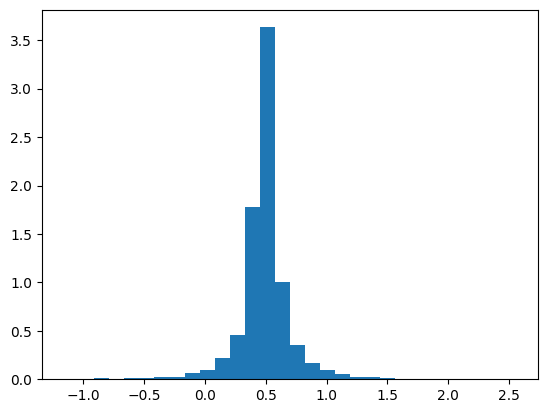

In [ ]:
mX = 0.7
n = 10000
xq = gauge_couplings['Chargephobic'][0:3]
s_tot = 42 # JLab 22GeV

#ex,cosx samples
X_kin_samples = mcmc_sample_EX_cosX(n,s_tot,malcolm_params,mX,xq)
EX_samples = X_kin_samples[:,0]
cosX_samples = X_kin_samples[:,1]

#pion p lab samples
pion_four_momenta_samples_in_X = sample_pion_four_momenta_in_X(n,mX)
pion_four_momenta_samples_in_lab = transform_restX_to_lab(EX_samples, cosX_samples, mX, pion_four_momenta_samples_in_X)

#the next thing
draw_mX_error(pion_four_momenta_samples_in_lab,EX_samples,cosX_samples,0.01,0.01)

# Computing reconstructed mass from samples

In [ ]:
## PARAMETERS ##
mX = 0.9
s_tot = 42
n = 1000
xq = gauge_couplings['Chargephobic'][0:3]

## EX, COSX SAMPLES ##
EX_cosX_samples = mcmc_sample_EX_cosX(n,s_tot,malcolm_params,mX,xq)
EX_samples = EX_cosX_samples[:,0]
cosX_samples = EX_cosX_samples[:,1]

## PION X_FRAME SAMPLES ##
pi_4momentums_X = sample_pion_four_momenta_in_X(n,mX)

## PION LAB_FRAME SAMPLES ##
pi_4momentums_LAB = transform_restX_to_lab(EX_samples,cosX_samples,mX,pi_4momentums_X)

## MASS RECONSTRUCTION TEST ##
pi_plus_4mom , pi_minus_4mom = pi_4momentums_LAB
E_plus = pi_plus_4mom[:,0]
E_minus = pi_minus_4mom[:,0]
p_plus = pi_plus_4mom[:,1:4]
p_minus = pi_minus_4mom[:,1:4]

counter = 0
for i in range(len(EX_samples)):
  reconstructed_mass = np.sqrt((E_plus[i]+E_minus[i])**2 - np.abs(np.linalg.norm(p_plus[i] + p_minus[i]))**2)
  if reconstructed_mass - mX < 0.001:
    counter += 1
print(f'convergence of reconstructed masses: {counter/len(EX_samples)}')
print(f'reconstructed mass value: {reconstructed_mass}')

convergence of reconstructed masses: 1.0
reconstructed mass value: 0.9000000000000012


#Notes

* s_tot = 2.5 , mX = 0.7 causes cross section to evaluate to zero. This didnt matter for summer result since s_tot was fixed by jefferson lab experiment.
